# A/B-тест Cookie Cats

**Бизнес-вопрос:** влияет ли перенос первых игровых ворот с 30-го на 40-й уровень на Day-7 retention?

`gate_30` — контроль, `gate_40` — тест. Основная метрика — Day-7 retention. В ноутбуке есть проверки качества данных, сравнение долей, доверительные интервалы и отдельный взгляд на игровую активность.

Если исходный CSV ещё не скачан, будет использована синтетическая демонстрационная выборка. Результаты на ней не относятся к оригинальному эксперименту.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, chisquare
from statsmodels.stats.proportion import proportions_ztest, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW_FILE = ROOT / "data" / "raw" / "cookie_cats.csv"
DEMO_FILE = ROOT / "data" / "demo" / "cookie_cats_demo.csv"
OUT_FIG = ROOT / "reports" / "figures"
OUT_TAB = ROOT / "reports" / "tables"
OUT_FIG.mkdir(parents=True, exist_ok=True)
OUT_TAB.mkdir(parents=True, exist_ok=True)

if RAW_FILE.exists():
    file_path = RAW_FILE
    data_type = "оригинальный публичный Cookie Cats dataset"
else:
    file_path = DEMO_FILE
    data_type = "ДЕМО: синтетическая выборка, не оригинальный эксперимент"

print("Источник данных:", data_type)
df = pd.read_csv(file_path)
df.head()

Источник данных: ДЕМО: синтетическая выборка, не оригинальный эксперимент


,userid,version,sum_gamerounds,retention_1,retention_7
0,1,gate_40,12,1,0
1,2,gate_40,33,0,0
2,3,gate_30,27,1,0
3,4,gate_30,1,0,1
4,5,gate_30,12,1,0


## 1. Проверка данных

Перед расчётом метрик проверяю размер таблицы, пропуски, дубликаты пользователей, группы и допустимые значения.

In [2]:
print("Размер:", df.shape)
print("Пропуски:", df.isna().sum())
print("Дубликаты userid:", df.userid.duplicated().sum())
print("Группы:", df.version.value_counts())
print("Неправильные группы:", set(df.version.dropna().unique()) - {"gate_30", "gate_40"})
print("Отрицательные game rounds:", (df.sum_gamerounds < 0).sum())
print("Уникальные значения retention_1:", sorted(df.retention_1.dropna().unique()))
print("Уникальные значения retention_7:", sorted(df.retention_7.dropna().unique()))

Размер: (6000, 5)
Пропуски: userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64
Дубликаты userid: 0
Группы: version
gate_40    3000
gate_30    3000
Name: count, dtype: int64
Неправильные группы: set()
Отрицательные game rounds: 0
Уникальные значения retention_1: [np.int64(0), np.int64(1)]
Уникальные значения retention_7: [np.int64(0), np.int64(1)]


## 2. SRM — проверка распределения пользователей

Если эксперимент планировался как 50/50, проверяю, насколько фактический размер групп отличается от ожидаемого распределения. При маленьком p-value это сигнал проверить назначение пользователей, логику фильтрации и сбор данных. Это не диагноз причины.

In [3]:
counts = df["version"].value_counts().reindex(["gate_30", "gate_40"])
expected = np.array([len(df) / 2, len(df) / 2])
srm_stat, srm_p = chisquare(counts.values, f_exp=expected)
srm_result = pd.DataFrame({"group": counts.index, "users": counts.values,
                           "share": counts.values / len(df)})
print(f"SRM chi-square = {srm_stat:.3f}; p-value = {srm_p:.4f}")
print("При alpha=0.05:", "есть повод проверить распределение" if srm_p < 0.05 else "сильного отклонения не обнаружено")
srm_result

SRM chi-square = 0.000; p-value = 1.0000
При alpha=0.05: сильного отклонения не обнаружено


,group,users,share
0,gate_30,3000,0.5
1,gate_40,3000,0.5


## 3. Основные показатели по группам

Сначала считаю простые доли возврата. Дальше проверю, насколько разница может объясняться случайной вариацией.

In [4]:
metrics = (df.groupby("version")
           .agg(users=("userid", "nunique"),
                retention_1=("retention_1", "mean"),
                retention_7=("retention_7", "mean"),
                median_rounds=("sum_gamerounds", "median"),
                mean_rounds=("sum_gamerounds", "mean"))
           .reindex(["gate_30", "gate_40"]))
metrics

,users,retention_1,retention_7,median_rounds,mean_rounds
version,,,,,
gate_30,3000,0.451333,0.194333,12.0,14.672
gate_40,3000,0.433333,0.174333,11.0,14.026


## 3.1. Распределение игровых раундов и возможные выбросы

Проверяю квантили и самые большие значения. Экстремальные значения не удаляю автоматически: сначала нужно понять, является ли это ошибкой данных или редким, но возможным поведением игрока.

In [5]:
rounds_summary = df["sum_gamerounds"].describe(percentiles=[0.5, 0.9, 0.99, 0.999])
rounds_summary

count    6000.000000
mean       14.349000
std        10.879228
min         0.000000
50%        12.000000
90%        29.000000
99%        51.000000
99.9%      71.001000
max        85.000000
Name: sum_gamerounds, dtype: float64

In [6]:
# Смотрю несколько самых больших значений и проверяю, в какой группе они находятся.
df.nlargest(10, "sum_gamerounds")[["userid", "version", "sum_gamerounds", "retention_1", "retention_7"]]

,userid,version,sum_gamerounds,retention_1,retention_7
371,372,gate_30,85,0,0
3652,3653,gate_40,78,1,0
2359,2360,gate_30,77,1,0
4524,4525,gate_30,76,1,1
233,234,gate_30,75,0,0
1114,1115,gate_40,72,0,0
3118,3119,gate_30,71,1,0
650,651,gate_40,70,0,0
4408,4409,gate_40,68,0,0
1298,1299,gate_40,67,0,0


Большое значение `sum_gamerounds` может заметно влиять на среднее. Поэтому в сравнении вовлечённости ниже дополнительно смотрю медианы и использую Mann–Whitney U. Само по себе большое число раундов не является достаточным основанием удалять пользователя.

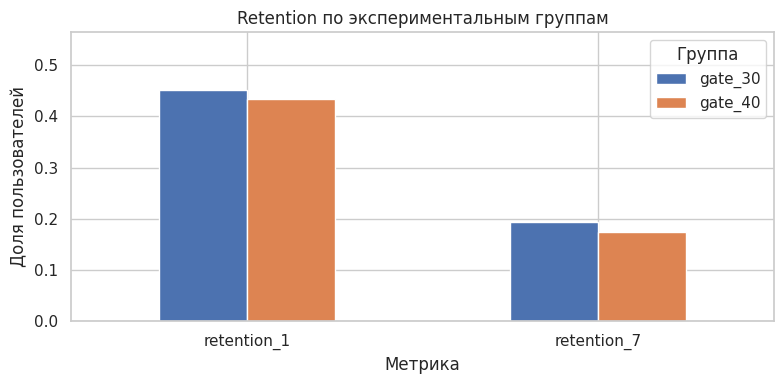

In [7]:
plot_data = metrics[["retention_1", "retention_7"]].T
ax = plot_data.plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_title("Retention по экспериментальным группам")
ax.set_xlabel("Метрика")
ax.set_ylabel("Доля пользователей")
ax.set_ylim(0, max(plot_data.max()) * 1.25)
ax.legend(title="Группа")
plt.tight_layout()
plt.savefig(OUT_FIG / "retention_by_group.png", dpi=150)
plt.show()
metrics.to_csv(OUT_TAB / "group_metrics.csv")

## 4. Проверка Day-7 retention

Поскольку retention — бинарная метрика, сравниваю две доли с помощью двухвыборочного z-теста. Дополнительно рассчитываю 95% Wald CI для разницы долей и Cohen's h как оценку размера эффекта.

Порядок разницы ниже: `gate_40 - gate_30`. Отрицательное значение означает, что retention в тестовой группе ниже.

In [8]:
def compare_proportions(data, metric):
    control = data.loc[data.version == "gate_30", metric].astype(int)
    treatment = data.loc[data.version == "gate_40", metric].astype(int)
    n_c, n_t = len(control), len(treatment)
    p_c, p_t = control.mean(), treatment.mean()
    diff = p_t - p_c
    se = np.sqrt(p_c * (1 - p_c) / n_c + p_t * (1 - p_t) / n_t)
    ci_low, ci_high = diff - 1.96 * se, diff + 1.96 * se
    z_stat, p_value = proportions_ztest(
        count=[treatment.sum(), control.sum()],
        nobs=[n_t, n_c],
        alternative="two-sided"
    )
    cohens_h = proportion_effectsize(p_t, p_c)
    return {
        "metric": metric,
        "control_rate": p_c,
        "treatment_rate": p_t,
        "difference_pp": diff * 100,
        "ci_low_pp": ci_low * 100,
        "ci_high_pp": ci_high * 100,
        "z_stat": z_stat,
        "p_value": p_value,
        "cohens_h": cohens_h,
        "n_control": n_c,
        "n_treatment": n_t,
    }

primary = compare_proportions(df, "retention_7")
pd.Series(primary)

metric            retention_7
control_rate         0.194333
treatment_rate       0.174333
difference_pp            -2.0
ci_low_pp           -3.961662
ci_high_pp          -0.038338
z_stat               -1.99764
p_value              0.045756
cohens_h            -0.051596
n_control                3000
n_treatment              3000
dtype: object

In [9]:
alpha = 0.05
print(f"Разница Day-7 retention: {primary['difference_pp']:.2f} п.п.")
print(f"95% CI: [{primary['ci_low_pp']:.2f}; {primary['ci_high_pp']:.2f}] п.п.")
print(f"p-value: {primary['p_value']:.4f}")
if primary["p_value"] < alpha:
    print("При alpha=0.05 нулевая гипотеза отвергается: разница статистически значима.")
else:
    print("При alpha=0.05 нет оснований отвергнуть нулевую гипотезу.")

Разница Day-7 retention: -2.00 п.п.
95% CI: [-3.96; -0.04] п.п.
p-value: 0.0458
При alpha=0.05 нулевая гипотеза отвергается: разница статистически значима.


## 5. Bootstrap-интервал для разницы

Для дополнительной проверки строю bootstrap-интервал для `gate_40 - gate_30`. Так как метрика бинарная, количество единиц в bootstrap-выборке можно моделировать биномиальным распределением с наблюдаемой долей каждой группы. Это эквивалентно повторной выборке бинарных наблюдений с возвращением.

In [10]:
control = df.loc[df.version == "gate_30", "retention_7"].astype(int).to_numpy()
treatment = df.loc[df.version == "gate_40", "retention_7"].astype(int).to_numpy()
rng = np.random.default_rng(42)
B = 3000
boot_control = rng.binomial(len(control), control.mean(), size=B) / len(control)
boot_treatment = rng.binomial(len(treatment), treatment.mean(), size=B) / len(treatment)
boot_diff_pp = (boot_treatment - boot_control) * 100
boot_ci = np.quantile(boot_diff_pp, [0.025, 0.975])
print(f"Bootstrap 95% CI: [{boot_ci[0]:.2f}; {boot_ci[1]:.2f}] п.п.")

Bootstrap 95% CI: [-3.87; 0.00] п.п.


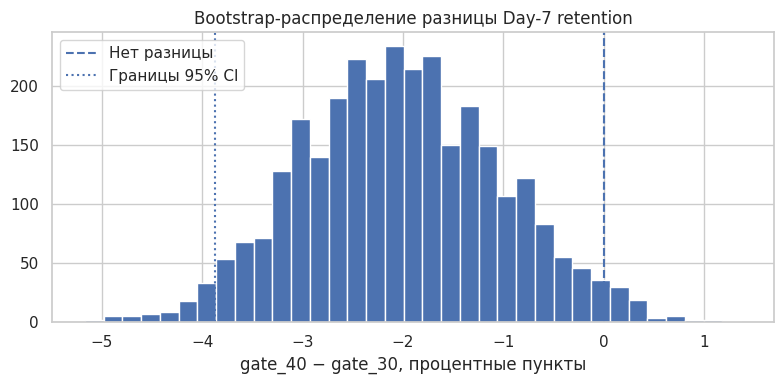

In [11]:
plt.figure(figsize=(8, 4))
plt.hist(boot_diff_pp, bins=35, edgecolor="white")
plt.axvline(0, linestyle="--", label="Нет разницы")
plt.axvline(boot_ci[0], linestyle=":", label="Границы 95% CI")
plt.axvline(boot_ci[1], linestyle=":")
plt.title("Bootstrap-распределение разницы Day-7 retention")
plt.xlabel("gate_40 − gate_30, процентные пункты")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_FIG / "bootstrap_day7_difference.png", dpi=150)
plt.show()

## 6. Дополнительные проверки

Day-1 retention рассматриваю как вторичную метрику. Для `sum_gamerounds` использую Mann–Whitney U: распределение игровых раундов обычно скошено, поэтому сравнивать только средние значения не очень полезно.

In [12]:
secondary = compare_proportions(df, "retention_1")
print("Day-1 retention")
print(f"Разница: {secondary['difference_pp']:.2f} п.п.; p-value: {secondary['p_value']:.4f}")

rounds_control = df.loc[df.version == "gate_30", "sum_gamerounds"]
rounds_treatment = df.loc[df.version == "gate_40", "sum_gamerounds"]
u_stat, u_p = mannwhitneyu(rounds_control, rounds_treatment, alternative="two-sided")
print("Game rounds")
print("Медиана gate_30:", rounds_control.median())
print("Медиана gate_40:", rounds_treatment.median())
print(f"Mann–Whitney U p-value: {u_p:.4f}")

Day-1 retention
Разница: -1.80 п.п.; p-value: 0.1604
Game rounds
Медиана gate_30: 12.0
Медиана gate_40: 11.0
Mann–Whitney U p-value: 0.0061


## 7. Оценка размера выборки (дополнительно)

Для ориентира считаю, сколько пользователей нужно в каждой группе, чтобы обнаруживать разницу порядка 1 процентного пункта при alpha=5% и мощности 80%, используя наблюдаемую базовую Day-7 retention в контроле. Это ретроспективная оценка для учебного проекта, а не исходный план эксперимента.

In [13]:
baseline = df.loc[df.version == "gate_30", "retention_7"].mean()
target_rate = min(baseline + 0.01, 0.999)
effect_size = abs(proportion_effectsize(target_rate, baseline))
power_analysis = NormalIndPower()
required_n = power_analysis.solve_power(effect_size=effect_size, power=0.80, alpha=0.05, ratio=1.0)
print(f"Контрольный baseline: {baseline:.2%}")
print(f"Ориентир: +1 п.п.")
print(f"Оценка размера группы: около {np.ceil(required_n):.0f} пользователей")

Контрольный baseline: 19.43%
Ориентир: +1 п.п.
Оценка размера группы: около 25050 пользователей


## 8. Итоговая рекомендация

Для решения смотрю в первую очередь на Day-7 retention, потому что она заранее выбрана основной метрикой. Статистическую значимость не приравниваю к бизнес-эффекту. Допущение проекта: эффект меньше 1 п.п. сам по себе считаю небольшим и требующим оценки бизнес-ценности.

In [14]:
if primary["p_value"] < 0.05 and primary["ci_high_pp"] < 0:
    direction = "тестовый вариант снижает Day-7 retention"
elif primary["p_value"] < 0.05 and primary["ci_low_pp"] > 0:
    direction = "тестовый вариант повышает Day-7 retention"
else:
    direction = "убедительных статистических доказательств различия Day-7 retention нет"

print("Результат:", direction)
print(f"Оценка разницы: {primary['difference_pp']:.2f} п.п.")
print(f"95% CI: [{primary['ci_low_pp']:.2f}; {primary['ci_high_pp']:.2f}] п.п.")
if primary["p_value"] < 0.05 and primary["difference_pp"] < 0:
    print("Предварительная рекомендация: не выкатывать gate_40 без дополнительного объяснения негативного эффекта.")
elif primary["p_value"] >= 0.05:
    print("Предварительная рекомендация: данных недостаточно, чтобы заявить об улучшении; обсудить продолжение/повтор эксперимента.")
else:
    print("Предварительная рекомендация: рассмотреть выкатывание после проверки guardrail-метрик и бизнес-эффекта.")

print("Важно: перед выводом проверьте, что ноутбук использует оригинальный CSV, а не DEMO-выборку.")

Результат: тестовый вариант снижает Day-7 retention
Оценка разницы: -2.00 п.п.
95% CI: [-3.96; -0.04] п.п.
Предварительная рекомендация: не выкатывать gate_40 без дополнительного объяснения негативного эффекта.
Важно: перед выводом проверьте, что ноутбук использует оригинальный CSV, а не DEMO-выборку.


## Ограничения

- Неизвестно, сколько пользователей реально дошли до игровых ворот. Анализ отражает эффект назначения в группу, а не эффект среди увидевших ворота.
- Нет данных о выручке, оплатах и удалениях приложения.
- В проекте используется простой Wald CI; при необходимости стоит проверить интервалы Уилсона/Newcombe.
- SRM — только диагностическая проверка; причину отклонения нужно искать в механике рандомизации и логировании.
- 1 п.п. — учебный ориентир, который в реальном продукте нужно согласовать с экономикой и стоимостью изменения.